# Person reaching

Loads `outputs/person_avoiding/` and isolates each run's steady-state window.

A pair of runs, `no_gauss` and `gauss` (500 N/m), goals placed by hand around a person's arm
at x = −0.25 m. `TAU_LIMIT` is 0.35 N·m (button-pressing's is 0.25). No load cell, so the two
numbers that matter are geometric: clearance from the person, and whether the tip still
reaches the button — both as 3-D distances, printed below.

Whole-body-shaping claim: the tip reaches the same button whether the field is on or off; the
field buys clearance for everything behind it.

Position and strength are read from the run itself, never the config — goals were dragged
live, and a level switched off mid-run via the GUI tickbox reads back as applied.

**The arm leaves the y = 0 plane by up to 16 cm** (goal z re-tracks its own attachment point
each tick, gravity along -y), so the geometry figure below (X-Y, top-down) is a projection,
not the whole picture — the printed clearance/reach numbers above are the true 3-D ones.

Older runs carry a smaller field set; the cells below adapt to what's present.


In [1]:
import sys, os, importlib.util
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_1P5, FIG_W_DOUBLE, set_font_size
from FK_Multi import FK_Multi
from VMC_utils.ConfigHelpers import strip_repeat

# plot_config.py's COLORS is the repo-wide pastel palette (a later, unrelated
# change) -- but every figure already saved in this notebook was built with
# the ORIGINAL vivid "npg" palette (before that pastel-ization), so importing
# today's COLORS and re-running would silently repaint every existing plot
# here pastel. Overriding it locally keeps this notebook's figures matching
# what's already saved, independent of whatever plot_config.py defaults to
# later.
COLORS = ['#4DBBD5', '#E64B35', '#00A087', '#3C5488', '#F39B7F',
         '#8491B4', '#91D1C2', '#DC0000', '#7E6148', '#B09C85']

GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

import glob
import numpy as np
import matplotlib.pyplot as plt

G_TO_N = 9.80665e-3   # load cell reports grams
S_BACKBONE = np.linspace(0.0, 1.0, 25)
SETTLE_S = 1.0        # [s] dropped from the front of a hold window, to let the arm arrive


def save_fig(fig, folder, name):
    """Every figure as PDF and SVG, next to the runs it came from."""
    for ext in ('pdf', 'svg'):
        fig.savefig(os.path.join('outputs', folder, f'{name}.{ext}'))


def nice(label):
    """Legend-ready text: no underscores, starts with a capital letter."""
    return label.replace('_', ' ').capitalize()

In [2]:
def load_cfg(name):
    """Import a config variant by file name without copying it into place."""
    spec = importlib.util.spec_from_file_location('cfg_' + name, f'GUI_MultiVMC_Config_{name}.py')
    mod  = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


def list_runs(folder):
    """Every run recorded in outputs/<folder>/, by name.

    A run that didn't exit cleanly can leave `<run>.autosave.npz` (last 30 s
    checkpoint, readable) or `<run>.npz.part.npz` (truncated, skipped)."""
    names = []
    for path in sorted(glob.glob(os.path.join('outputs', folder, '*.npz'))):
        name = os.path.splitext(os.path.basename(path))[0]
        if name.endswith('.part'):
            print(f'[skip] {name}.npz -- interrupted write, not readable')
            continue
        if name.endswith('.autosave'):
            print(f'[note] {name}.npz is a checkpoint: the run did not exit cleanly, '
                  'so it ends at the last one taken')
        names.append(name)
    return names


def hold_window(d, tol=1e-9, settle=SETTLE_S, mark_index=0):
    """The measurement window.

    With an operator mark (Ctrl+C when the tip reached the button), the window
    starts there and runs until something moves again; `mark_index` picks which
    mark. Without one, falls back to the longest stretch where nothing moved
    (goal x/y, spring/damper params) -- can't tell "on the button" from "let go
    of the mouse", and can span a mid-run stiffness change.

    Goal z is excluded from the motion check: in `_person`/`_card_castle`
    (GOAL_Z_TRACK) it re-tracks the attachment point every tick and wiggles at
    ~1e-5 m from FK noise even when still, which fragmented the hold into single
    ticks. `_button`'s locked z is unaffected either way.

    Drops the first SETTLE_S so the arm's arrival isn't averaged in."""
    t   = d['t']
    sig = [d['goal'][:, :, :2].reshape(len(t), -1), d['k_params']]
    if 'c_params' in d:
        sig.append(d['c_params'])
    sig = np.hstack([np.asarray(s, dtype=float) for s in sig])

    changed = np.r_[True, np.abs(np.diff(sig, axis=0)).max(axis=1) > tol]
    seg     = np.cumsum(changed)

    marks = np.asarray(d.get('marks_t', []), dtype=float)
    marks = marks[np.isfinite(marks) & (marks >= t[0]) & (marks <= t[-1])]
    if len(marks) > mark_index:
        m0   = marks[mark_index]
        hold = (seg == seg[int(np.searchsorted(t, m0))]) & (t >= m0)
    else:
        hold = seg == np.bincount(seg).argmax()

    trimmed = hold & (t >= t[hold][0] + settle) if hold.any() else hold
    return trimmed if trimmed.any() else hold   # a mark right before Ctrl+C


def load_run(folder, name):
    """One run: hold window marked, newer log channels passed through when present."""
    raw = np.load(os.path.join('outputs', folder, name + '.npz'), allow_pickle=True)
    d   = {k: raw[k] for k in raw.files}   # forces the read now, not lazily

    hold     = hold_window(d)
    tip_goal = d['goal'][:, 0, :]
    k_gauss  = d['k_params'][:, 1]

    r = dict(name=name, folder=folder, raw=d, t=d['t'], hold=hold,
             goal=d['goal'], comp_pos=d['comp_pos'],
             q_motor=d['q_motor'], tau=d['tau'],
             k_params=d['k_params'], k_gauss=k_gauss,
             force_n=d['force'] * G_TO_N,
             s_params=d['comp_s_params'],
             comp_names=[str(n) for n in d['comp_names']],
             tau_limit=float(d['tau_limit'][0]),
             strength=float(k_gauss[hold].mean()),
             target=tip_goal[hold].mean(axis=0),
             obstacle=d['goal'][hold, 1, :].mean(axis=0))

    # ── Channels only newer runs carry ────────────────────────────────────────
    r['f_comp']    = d.get('f_comp')            # (n, N_VC, 3) [N] per element
    r['comp_vel']  = d.get('comp_vel')          # (n, N_VC, 3) [m/s]
    r['c_params']  = d.get('c_params')
    r['force_age'] = d.get('force_age')
    r['tau_raw']   = d.get('tau_raw', d['tau'])  # pre-limiter torque, else the clipped one
    r['clipped']   = np.any(np.abs(r['tau_raw']) > r['tau_limit'] + 1e-12, axis=1)
    r['has_pre']   = bool((d['t'] < 0).any())    # logged before the GUI connected
    r['force_live'] = bool(np.any(d['force'] != 0.0))
    # Group repeats by condition (button: `weak_r1..r5`); a person/card_castle
    # run is one file per level, so it's its own group.
    r['condition']   = strip_repeat(name)
    r['repeat']      = name[len(r['condition']):].lstrip('_') or None
    r['marks_t']     = np.asarray(d.get('marks_t', []), dtype=float)
    r['marks_label'] = [str(x) for x in d.get('marks_label', [])]
    return r


def backbone(run, hold=None):
    """FK backbone at the mean pose over a window (the hold window by default)."""
    mask = run['hold'] if hold is None else hold
    q_ss = run['q_motor'][mask].mean(axis=0)
    return np.array([FK_Multi(q_ss, s)[:3] for s in S_BACKBONE])


def load_all(folder):
    """Every readable run in a folder; one bad file doesn't stop the rest."""
    runs = []
    for name in list_runs(folder):
        try:
            runs.append(load_run(folder, name))
        except Exception as exc:
            print(f'[skip] {name}.npz -- {type(exc).__name__}: {exc}')
    # Sweep order, not alphabetical -- `medium_r1` would sort before `no_gauss_r1`
    # and reverse the legend. Runs at one strength (person/card_castle) just sort by name.
    return sorted(runs, key=lambda r: (r['strength'], r['name']))


def summary(runs):
    for r in runs:
        b   = backbone(r)
        clr = np.linalg.norm(b - r['obstacle'], axis=1).min()
        tip = r['comp_pos'][r['hold'], 0, :].mean(axis=0)
        r['clearance']   = float(clr)
        r['reach_error'] = float(np.linalg.norm(r['target'] - tip))
        t = r['t'][r['hold']]
        print(f"{r['name']:>14}  strength {r['strength']:6.0f}  "
              f"hold {t[0]:6.1f}-{t[-1]:6.1f}s ({r['hold'].sum():6d} samples)  "
              f"clearance {clr*100:5.1f} cm  reach err {r['reach_error']*100:5.1f} cm  "
              f"clip {100*r['clipped'][r['hold']].mean():4.0f}%  "
              f"force {'live' if r['force_live'] else 'FLAT'}  "
              f"window {'marked' if len(r['marks_t']) else 'inferred'}")

In [3]:
cfg_p  = load_cfg('person')
runs_p = load_all('person_avoiding')
if not runs_p:
    print('outputs/person_avoiding/ is empty -- record the two levels first '
          '(README: --run no_gauss | gauss, one session each).')
else:
    summary(runs_p)
    missing = [c for c in cfg_p.GAUSS_CONDITIONS if c not in {r['name'] for r in runs_p}]
    if missing:
        print('\n[note] not recorded yet: ' + ', '.join(missing))

      no_gauss  strength      0  hold   26.2-  50.5s (  7991 samples)  clearance   8.8 cm  reach err  44.9 cm  clip    0%  force FLAT  window inferred
         gauss  strength    500  hold   34.3-  58.5s (  8011 samples)  clearance  13.4 cm  reach err  46.2 cm  clip    0%  force FLAT  window inferred


### Geometry

Top view (X-Y) directly above the side view (X-Z), sharing the X axis. Z points down the
page (0 at top, 25 cm at bottom); Y also runs up to 25 cm.

In [4]:
GEOMETRY_WIDTH = FIG_W_1P5   # in -- TUNE THIS: figure width
GEOMETRY_ASPECT_W, GEOMETRY_ASPECT_H = 50, 60   # TUNE THIS: width:height ratio, as two
                                                # integers (reproduces the old fixed
                                                # GEOMETRY_FIG_H=4.00in at this width)
GEOMETRY_FIG_H = GEOMETRY_WIDTH * GEOMETRY_ASPECT_H / GEOMETRY_ASPECT_W
GEOMETRY_LEGEND_FONT = 13   # TUNE THIS: legend text size
# ^ total figure height [in] -- both panels are aspect='equal' and share one
# x-axis, so this is what actually tightens the gap between them (gridspec
# hspace has no real effect here -- see the height_ratios fix at the end below)

def plot_geometry(runs, cfg, folder, obstacle_label='obstacle', name='backbone'):
    obs = runs[0]['obstacle']
    tgt = runs[0]['target']

    # Top view directly above the side view, sharing the X axis -- the classic
    # third-angle-projection layout: a feature's X position lines up between
    # the two rows.
    fig, (ax_xy, ax_xz) = plt.subplots(
        2, 1, figsize=(GEOMETRY_WIDTH, GEOMETRY_FIG_H), sharex=True, layout='constrained')

    conds = sorted({r['condition'] for r in runs},
                   key=lambda c: next(x['strength'] for x in runs if x['condition'] == c))
    seen = set()
    for r in runs:
        i   = conds.index(r['condition'])          # colour by condition, not by file
        b   = backbone(r)
        # Condition name only, no strength number -- 'no_gauss'/'gauss' are the
        # only two cases here, so the field is either off or on.
        lbl = None if r['condition'] in seen else (
            'No gaussian' if r['condition'] == 'no_gauss' else 'Gaussian')
        seen.add(r['condition'])
        ax_xy.plot(b[:, 0] * 100, b[:, 1] * 100, color=COLORS[i], linewidth=2.0,
                   alpha=0.85, zorder=3, label=lbl)
        ax_xz.plot(b[:, 0] * 100, b[:, 2] * 100, color=COLORS[i], linewidth=2.0,
                   alpha=0.85, zorder=3)
        for s in r['s_params'][1:]:            # the Gaussian attachment points
            p = b[np.argmin(np.abs(S_BACKBONE - s))]
            ax_xy.plot(p[0] * 100, p[1] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)
            ax_xz.plot(p[0] * 100, p[2] * 100, 'o', color=COLORS[i], markersize=4, zorder=4)

    for a, v, vl in ((ax_xy, 1, 'Y (cm)'), (ax_xz, 2, 'Z (cm)')):
        a.plot(tgt[0] * 100, tgt[v] * 100, '*', color='k', markersize=13, zorder=5,
               label='Target' if a is ax_xy else None)
        a.plot(obs[0] * 100, obs[v] * 100, 'X', color='k', markersize=9, zorder=5,
               label=nice(obstacle_label) if a is ax_xy else None)
        # The true silhouette of a sphere of radius sigma -- and the trap: a
        # backbone drawn inside it is not necessarily within sigma in 3-D.
        a.add_patch(plt.Circle((obs[0] * 100, obs[v] * 100), cfg.SIGMA * 100, fill=False,
                               linestyle='--', color='k', linewidth=0.9, alpha=0.5, zorder=2))
        a.set_ylabel(vl)
        a.set_aspect('equal'); a.grid(GRID)

    ax_xy.set_ylim(top=30)          # Y up to 25 cm
    ax_xz.set_ylim(25, 0)           # Z up to 25 cm, points down the page

    ax_xz.set_xlabel('X (cm)')
    ax_xy.legend(fontsize=GEOMETRY_LEGEND_FONT, loc='lower left', framealpha=0.9)

    # Both panels are aspect='equal' sharing one x-axis, so each one's true
    # rendered height is fixed by (its own y-range / the shared x-range) at a
    # given width. Equal (default) gridspec row heights let whichever panel
    # needs more height run out first -- matplotlib then narrows THAT panel
    # instead of shortening it, which breaks the shared x-axis alignment.
    # Matching each row's height budget to its own y-range keeps both at full
    # width regardless of how tight GEOMETRY_FIG_H is set above.
    fig.canvas.draw()
    range_xy = abs(ax_xy.get_ylim()[1] - ax_xy.get_ylim()[0])
    range_xz = abs(ax_xz.get_ylim()[1] - ax_xz.get_ylim()[0])
    ax_xy.get_gridspec().set_height_ratios([range_xy, range_xz])

    save_fig(fig, folder, name)
    plt.show()

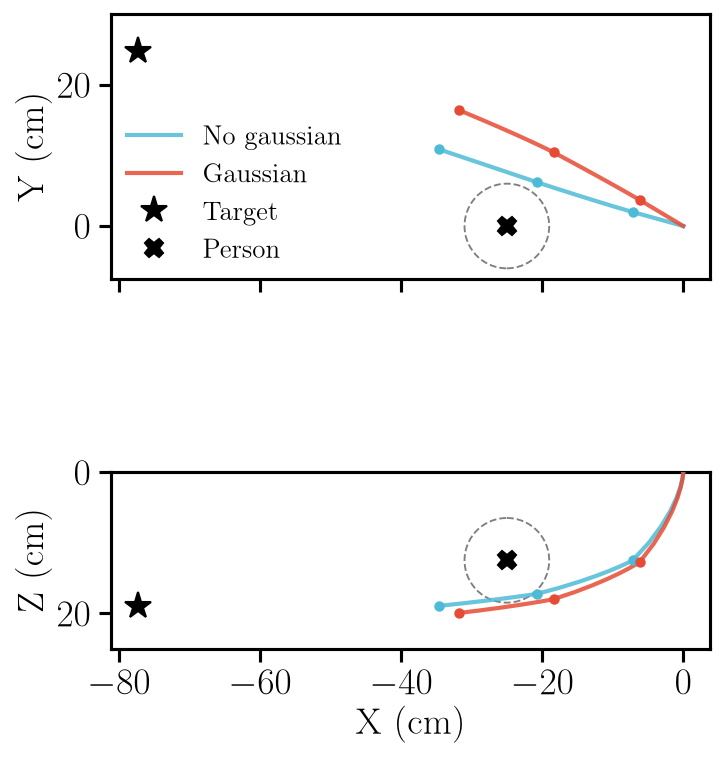

In [5]:
if runs_p:
    plot_geometry(runs_p, cfg_p, 'person_avoiding', obstacle_label='person')